# Forward-add test for the hybrid's regressors (none kept)

**The question:** did the hybrid's input pruning drop something the trees could use?

**Background:** the hybrid's 30 regressors (set C) keep one window per family, chosen by the linear
model's single-feature ranking, plus extra coronal-hole lags. All 24 families are in, so what set C
dropped are the other windows of each family: 90 in all, 17 of them coronal-hole lags (timed
separately in `training.lead_aligned_ch`).

**The test** (`python -m training.hybrid_forward_add`): for each of the 19 families with unused
windows, the unused window furthest (in log hours) from the one in use is added to the shipped 30,
one family at a time; "+ all" adds all 19. The trees are refitted with the shipped settings on the
shipped linear model. Six yearly walk-forward folds (2019-10 → 2025-10); score: per-run mean TIMSE
/ persistence, geometric mean over folds. The eval year is not used.

**Keep rule (set before running):** more than 0.5% better than the shipped hybrid, winning at least
4 of 6 folds.

1. Scores
2. By fold
3. Findings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import hybrid_forward_add as fa

df = pd.read_csv(fa.EXPERIMENTS / "hybrid_forward_add.csv").set_index("fold")
cols = [c for c in df.columns if c.startswith("hybrid")]
ref = "hybrid shipped"


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


summary = pd.DataFrame({c: {"score": geo(c), "vs shipped": geo(c) / geo(ref) - 1,
                            "folds won": int((df[c] < df[ref]).sum())}
                        for c in cols}).T.sort_values("score")
summary["keep"] = (summary["vs shipped"] < -fa.KEEP_GAIN) & (summary["folds won"] >= fa.KEEP_FOLDS)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)

,score,vs shipped,folds won,keep
hybrid + log_p310_mean_48h,0.4241,-0.0027,3.0000,False
hybrid + speed_mean_1h,0.4244,-0.0021,5.0000,False
hybrid + log_t_ratio_mean_48h,0.4247,-0.0015,3.0000,False
hybrid + m_flares_count_24h,0.4249,-0.0009,3.0000,False
hybrid + density_slope_6h,0.4250,-0.0006,4.0000,False
hybrid + polarity_mean_1h,0.4251,-0.0004,3.0000,False
hybrid + xray_peak_max_24h,0.4252,-0.0003,3.0000,False
hybrid shipped,0.4253,0.0000,0.0000,False
hybrid + log_temperature_mean_48h,0.4254,0.0002,4.0000,False
hybrid + bt_max_48h,0.4254,0.0003,2.0000,False


## 2. By fold (% change against the shipped hybrid)

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
+ log_p310_mean_48h,0.2,-1.3,0.3,0.1,-0.3,-0.7
+ speed_mean_1h,-0.3,-0.2,-0.8,-0.1,-0.4,0.5
+ log_t_ratio_mean_48h,0.2,-0.9,-1.0,-0.4,0.2,1.0
+ m_flares_count_24h,0.0,-0.2,-0.9,0.7,-0.5,0.3
+ density_slope_6h,0.4,-0.3,-1.0,-0.1,-0.1,0.7
+ polarity_mean_1h,0.0,-0.8,-0.9,0.7,-0.2,1.0
+ xray_peak_max_24h,1.6,-0.9,-1.0,0.9,-1.2,0.4
+ log_temperature_mean_48h,1.2,-0.7,-0.4,-0.1,-0.3,0.4
+ bt_max_48h,0.5,1.2,-2.1,0.3,0.3,-0.1
+ bz_min_3h,0.0,-0.2,-0.9,0.7,-0.2,0.8


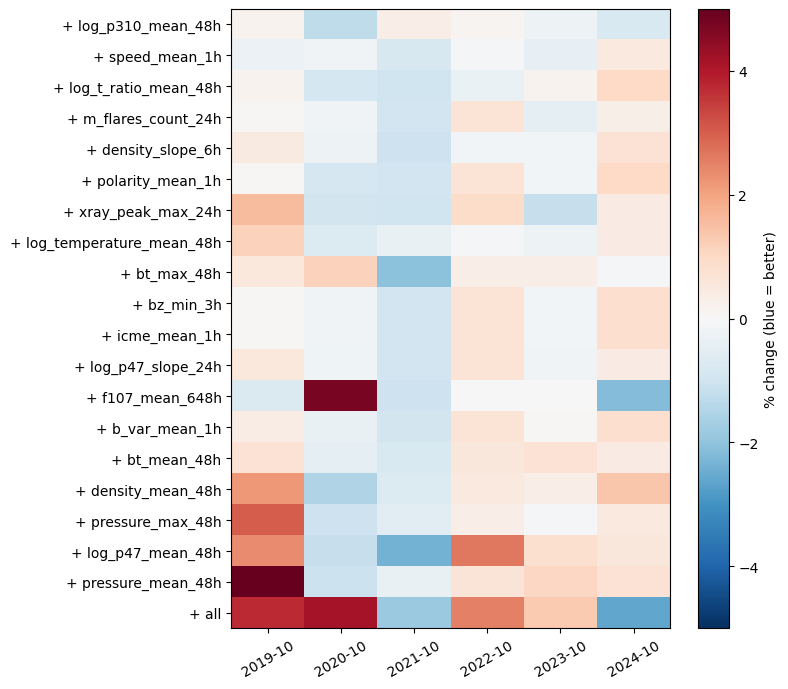

In [2]:
change = pd.DataFrame({c.removeprefix("hybrid "): 100 * (df[c] / df[ref] - 1)
                       for c in summary.index if c != ref})
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(change.T.to_numpy(), cmap="RdBu_r", vmin=-5, vmax=5, aspect="auto")
ax.set_yticks(range(change.shape[1]), change.columns)
ax.set_xticks(range(change.shape[0]), change.index, rotation=30)
plt.colorbar(im, label="% change (blue = better)")
plt.tight_layout()
display(change.T.round(1))

## 3. Findings

- **Nothing passes the keep rule** (more than 0.5% better and at least 4 of 6 folds). The best additions are the 48-hour mean of the ≥ 310 keV protons (−0.27%, 3 folds) and the 1-hour speed mean next to the 24-hour one (−0.21%, 5 folds). Both are within the trees' refit noise.
- **The 2024 pilot fold misled again.** The 27-day F10.7 mean gained 2.2% there and "+ all" 2.6%; over six folds they are +0.1% and +1.2%. The F10.7 mean loses 4.7% in the 2020 fold, the first fold after the solar minimum, where its level was new to the trees.
- **Adding everything hurts** (+1.2%, 2 of 6 folds). With 49 inputs the trees spend splits on redundant windows.
- **The answer to "was something useful dropped?" is no.** Every family is in the hybrid, and a second window of a family adds nothing the trees can use. Set C's pruning by the linear model's single-feature ranking didn't throw away signal.
- **Decision:** the hybrid's 30 inputs stay. `training.hybrid_forward_add` and this notebook are the record (`docs/hybrid_forward_add.md`).